# PHGarfield density-map generator (v35 geometry)

Small, fast generator of solver-ready maps for `PHGarfieldRossegger::setDensityMapFile`, for any radial power α:

ρ(r) = (R_ref/r)^α · T(r) · D(r)

- **T(r)**: inner turn-on (erf). With the data parameters the density peaks at ≈ 25–26 cm and drops toward the R1 GEM edge at 22.8 cm (seen in the antenna pads). `TURN_ON=False` gives a pure power law.
- **D(r)**: optional extra dip (position / width / depth), off by default.
- `"data"` = medians of the v35 fits over 47 run/windows (side 0: α=2.03, r0=22.75; side 1: α=1.90, r0=22.13; w=2 cm). A number replaces only α.
- Geometry exactly as v35: Rossegger radial bins, zero in the R1/R2 and R2/R3 gaps, below 22.8 cm and in the sector frames; dead stripes from `input/dead_stripes.csv`.
- `h_primary_phgarfield_real_side{0,1}` (no gain) and `h_ibf_phgarfield_real_side{0,1}` (× gain map × sector tune, corrected gain indexing), 216 and 1440 φ bins. Every map is also written as `*_South` / `*_North` (physical side; histogram `side0/side1` = DC side, DC side 0 = North). Use the `_South/_North` names in Rossegger. Same names as the v35 maps, so `input/RunPHGarfieldRossegger_v35DensityMap.C` takes these files directly.

- **Gain source** for the IBF map: `GAIN_SOURCE = "gain_map"` (dE/dx, run 79513) or `"dc_measured"` (sector pattern of the measured DC in the DC runs).
- **Ion-backflow fraction per GEM module** (`IBF_EPS_DAMAGED_G4`, `IBF_EPS_OVERRIDE`) using `input/undamaged_gem_channels.txt`; multiplies only the IBF map.

Edit the configuration cell and run all (a few seconds per α).

In [1]:
import os, math, glob
from pathlib import Path
from array import array
import numpy as np
import pandas as pd
from scipy.special import erf
import matplotlib.pyplot as plt
import ROOT as root
root.gROOT.SetBatch(True)
root.TH1.AddDirectory(False)

# ============================================================
# CONFIGURATION — edit here
# ============================================================
# One output file per entry. "data" = parameters fitted to the 47 run/windows
# (v35 stable map); a number = that alpha for both sides, other parameters from data.
ALPHAS = ["data", 1.25, 1.6, 2.0]

# rho(r) = (R_REF/r)^alpha * T(r) * D(r)
#   T(r): inner turn-on (erf, 50 % at r0, width w) -> density peaks at ~25-26 cm and
#         falls toward the R1 GEM edge at 22.8 cm, as seen in the antenna pads.
#   D(r): optional extra dip 1 - depth*exp(-(r-r_dip)^2/(2 w_dip^2)), off when depth = 0.
R_REF = 40.0
DATA_PARAMS = {                       # medians of the v35 fits (47 run/windows, primary)
    0: dict(alpha=2.028, r0=22.75, width=2.0),
    1: dict(alpha=1.903, r0=22.13, width=2.0),
}
TURN_ON = True                        # False: pure power law down to 22.8 cm
DIP = dict(r=None, width=1.0, depth=0.0)   # e.g. dict(r=30.0, width=1.0, depth=0.2)

# Geometry / gain
MAPPING_DIR = Path("/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/TPC/ChannelMapping1/PadPlane/")
GAIN_MAP_FILE = Path("../distort/input/layer_gain_79513_Mariia_side01.root")
GAIN_HISTS = ("hGainMap_side0_South", "hGainMap_side1_North")
APPLY_GAIN = True
# Verified on 19 runs: DC side s, sector k uses gain-map side 1-s, sector (5-k)%12.
GAIN_INDEXING = "idealpadmap_swapped"     # idealpadmap_swapped | rossegger_realtpc | native
# rossegger_realtpc reproduces the gain placement of PHGarfieldRossegger real-TPC mode
# (gain-map sector k at phi=(5-k)*30deg, mirrored w.r.t. the DC data) for an A/B test.
SECTOR_GAIN_TUNE = {0: [1.0]*12, 1: [1.0]*12}   # DC sector numbering, on top of the gain
ANTENNA_GAIN = "r1_median"               # gain for the antenna region: median R1 gain of the sector

# Gain source for the IBF map:
#   "gain_map"    : dE/dx gain map above (run 79513)
#   "dc_measured" : relative sector-to-sector DC response per row, measured in the DC runs
#                   (median over DC_GAIN_FILES; each row normalized to its median over sectors,
#                   then multiplied by the row median of the gain map so the radial part is unchanged)
GAIN_SOURCE = "gain_map"
DC_GAIN_FILES = "output_dc/TPC_DC_primary_density_v31_run*_win01.root"
DC_GAIN_HIST = "h_dc_density_recovered_rphi_ped60_signed_side{side}"

# Ion-backflow fraction per GEM module, multiplies ONLY the IBF map (primary x gain x eps).
# Modules are named as in input/undamaged_gem_channels.txt: S/N + sector 01..12 + R1..R3,
# using the gain-map side/sector numbering (S = hGainMap_side0_South = DC side 1, sector 01 at phi ~ 0).
GEM_STATUS_FILE = Path("input/undamaged_gem_channels.txt")
IBF_EPS_UNDAMAGED_G4 = 1.0
IBF_EPS_DAMAGED_G4 = 1.0                 # e.g. 1.5 -> 50 % more ion backflow from damaged-G4 modules
IBF_EPS_OVERRIDE = {}                    # e.g. {"S02R1": 2.0, "N02R1": 1.5}

# Sector-by-sector k_eff (IBF) correction from residual rDCA vs phi (see the k_eff cell).
# Source 1 (used if present): ROOT file from MakeResidualHistograms_loosemaps.C,
#   dirs side{0,1}_q{plus,minus}, h_rDCAzero_vs_atan2_px_py_vs_pt. NOTE: its x axis is
#   atan2(px,py) = pi/2 - phi; it is converted to phi = atan2(py,px) here.
RDCA_ROOT_FILE = Path("../drawings/input/pp_79513_fix_1p25_dip_nosurf.root")
RDCA_UNCORRECTED_ROOT_FILE = None          # optional same-format file reconstructed WITHOUT correction
RDCA_PT_RANGE = (0.3, 10.0)                # GeV/c, as in the median-rDCA plot (try (1.0, 10.0))
RDCA_PHI_REBIN = 1                         # 128 phi bins originally
RDCA_MIN_ENTRIES = 20
# Track side (z<0 = side 0, checked from eta) -> gain-map side. Default by the histogram
# names (hGainMap_side0_South). Mariia's module-gain txt labels side 0 "posz": if that is
# right, use {0: 1, 1: 0}.
RDCA_TRACK_SIDE_TO_GAIN_SIDE = {0: 0, 1: 1}
# Source 2: CSV columns side (track side), charge (+1/-1), phi (true phi, rad), rdca_cm, err_cm
RDCA_RESIDUAL_FILE = Path("input/rdca_vs_phi_corrected.csv")
RDCA_UNCORRECTED_FILE = Path("input/rdca_vs_phi_uncorrected.csv") # optional; else D0 below
RDCA_D0_CM = 1.5                  # |rDCA| without any correction (1.5 mm residual ~ 10 % k_eff)
RDCA_RELAXATION = 1.0             # < 1 to damp the update when iterating
RDCA_MAX_ABS_CM = 1.0             # drop phi bins with |rdca| above this (sector-edge spikes)
RDCA_KEFF_CLIP = (0.5, 2.0)
RDCA_KEFF_MODULES = (0, 1, 2)     # modules that get the sector factor (0/1/2 = R1/R2/R3)
RDCA_KEEP_MEAN = False            # True: only the sector-to-sector pattern, mean k_eff unchanged
RDCA_KEFF = {}                    # filled by the k_eff cell: {(DC side, DC sector): factor}

# Dead stripes: CSV side,sector,module,layer[,pad_lo,pad_hi]  (module 0/1/2 = R1/R2/R3,
# local layer 0..15, pads inclusive). Missing file = no dead stripes.
DEAD_STRIPE_FILE = Path("input/dead_stripes.csv")
SECTOR_FRAMES = True                     # zero charge between sectors (pad coverage)

PHI_BINS = (216, 1440)                   # 216 = setSourceGrid(..., 216, ...) in the Rossegger macro
OUTPUT_DIR = Path("output_dc/generated_maps")
DATA_STABLE_FILE = Path("output_dc/TPC_DC_phgarfield_stable_v35.root")   # for the data overlay only

# Rossegger density-map radial grid (PHGarfieldRossegger::buildSourceGrid)
ROSS_FIRST_LAYER_MM = (314.9835971194212, 416.5920253621078, 589.1096334932404)
ROSS_LAYER_HEIGHT_MM = (5.657908935192669, 10.206891263554285, 10.970474549405283)
ROSS_R1_GEM_INNER_CM = 22.8

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("alphas:", ALPHAS, "| data params:", DATA_PARAMS, "| dip:", DIP)


Welcome to JupyROOT 6.30/06
alphas: ['data', 1.25, 1.6, 2.0] | data params: {0: {'alpha': 2.028, 'r0': 22.75, 'width': 2.0}, 1: {'alpha': 1.903, 'r0': 22.13, 'width': 2.0}} | dip: {'r': None, 'width': 1.0, 'depth': 0.0}


## Geometry

In [2]:
# ============================================================
# Geometry: Rossegger radial bins, pad coverage per sector, dead stripes
# ============================================================
TWO_PI = 2*math.pi

def wrap_phi(p):
    return (np.asarray(p) + math.pi) % TWO_PI - math.pi

def load_rows():
    rows = {}
    for m in range(3):
        df = pd.read_csv(MAPPING_DIR/f"AutoPad-R{m+1}-RevA.sch.ChannelMapping.csv")
        for il in (range(-4, 16) if m == 0 else range(16)):
            r = df[df["Radius"] == il].sort_values("Pad")
            phi = r["PadPhi"].to_numpy(float)
            p = np.unwrap(phi)
            w = np.empty_like(p); w[1:-1] = 0.5*(p[2:] - p[:-2]); w[0] = p[1] - p[0]; w[-1] = p[-1] - p[-2]
            key = ("A", il + 4) if il < 0 else ("Z", m, il)
            rows[key] = {"r_cm": float(r["PadR"].mean())/10, "phi_local": phi, "w": np.abs(w), "n": len(r)}
    return rows

ROWS = load_rows()

def global_phi(row, side, sector, ip):
    """IdealPadMap side/sector convention (same as the v35 notebook)."""
    n = row["n"]
    cdb = row["phi_local"][ip if side == 0 else n - 1 - ip]
    mapped = (5 + 12 - sector % 12) % 12
    return float(wrap_phi((1.0 if side == 1 else -1.0)*(cdb - math.pi/2) + mapped*math.pi/6))

def rossegger_edges():
    first = [x/10 for x in ROSS_FIRST_LAYER_MM]; pitch = [x/10 for x in ROSS_LAYER_HEIGHT_MM]
    low = [f - 0.5*p for f, p in zip(first, pitch)]
    e, inner, x = [ROSS_R1_GEM_INNER_CM], [], low[0] - pitch[0]
    while x > ROSS_R1_GEM_INNER_CM + 1e-12:
        inner.append(x); x -= pitch[0]
    e += inner[::-1] + [low[0]] + [first[0] + (i + .5)*pitch[0] for i in range(16)]
    for m in (1, 2):
        e += [low[m]] + [first[m] + (i + .5)*pitch[m] for i in range(16)]
    e = np.array(e)
    kind = []
    for lo, hi in zip(e[:-1], e[1:]):
        rc = 0.5*(lo + hi); k = ("gap",)
        if rc < low[0]:
            k = ("A",)
        for m in range(3):
            for il in range(16):
                if first[m] + (il - .5)*pitch[m] - 1e-12 <= rc < first[m] + (il + .5)*pitch[m] - 1e-12:
                    k = ("Z", m, il)
        kind.append(k)
    return e, kind

R_EDGES, R_KIND = rossegger_edges()
NR = len(R_KIND)
ANT_R = np.array([ROWS[("A", a)]["r_cm"] for a in range(4)])

def row_for_bin(ir):
    k = R_KIND[ir]
    if k[0] == "Z":
        return ROWS[k]
    if k[0] == "A":
        rc = 0.5*(R_EDGES[ir] + R_EDGES[ir + 1])
        return ROWS[("A", int(np.argmin(np.abs(ANT_R - rc))))]
    return None

def interval_fraction(lo, hi, edges):
    out = np.zeros(len(edges) - 1)
    for k in (-1, 0, 1):
        a = np.maximum(edges[:-1], lo + k*TWO_PI); b = np.minimum(edges[1:], hi + k*TWO_PI)
        out += np.clip(b - a, 0, None)
    return np.clip(out/np.diff(edges), 0, 1)

def load_dead_stripes():
    if not DEAD_STRIPE_FILE.exists():
        return {}
    d = pd.read_csv(DEAD_STRIPE_FILE, comment="#", skipinitialspace=True)
    out = {}
    for _, r in d.iterrows():
        s, k, m, il = int(r["side"]), int(r["sector"]), int(r["module"]), int(r["layer"])
        n = ROWS[("Z", m, il)]["n"]
        lo = int(r["pad_lo"]) if "pad_lo" in d and pd.notna(r["pad_lo"]) else 0
        hi = int(r["pad_hi"]) if "pad_hi" in d and pd.notna(r["pad_hi"]) else n - 1
        out.setdefault((s, k, m, il), []).append((lo, hi))
    return out

DEAD = load_dead_stripes()
print(f"Rossegger radial bins: {NR}, r = {R_EDGES[0]:.3f}..{R_EDGES[-1]:.3f} cm; dead-stripe rows: {len(DEAD)}")

def live_fraction(side, nphi):
    """live[ir, sector, iphi] including sector frames and dead stripes."""
    edges = np.linspace(-math.pi, math.pi, nphi + 1)
    live = np.zeros((NR, 12, nphi))
    for ir in range(NR):
        row = row_for_bin(ir)
        if row is None:
            continue
        for k in range(12):
            ph = np.array([global_phi(row, side, k, ip) for ip in range(row["n"])])
            c = ph[row["n"]//2]; rel = np.arctan2(np.sin(ph - c), np.cos(ph - c))
            if SECTOR_FRAMES:
                lo, hi = c + np.min(rel - row["w"]/2), c + np.max(rel + row["w"]/2)
            else:
                mid = c + 0.5*(rel.min() + rel.max()); lo, hi = mid - math.pi/12, mid + math.pi/12
            f = interval_fraction(lo, hi, edges)
            kd = R_KIND[ir]
            if kd[0] == "Z":
                for plo, phi_ in DEAD.get((side, k, kd[1], kd[2]), []):
                    for ip in range(max(plo, 0), min(phi_, row["n"] - 1) + 1):
                        f = f - interval_fraction(c + rel[ip] - row["w"][ip]/2, c + rel[ip] + row["w"][ip]/2, edges)
            live[ir, k] = np.clip(f, 0, None)
    return edges, live

LIVE = {(s, n): live_fraction(s, n) for s in (0, 1) for n in PHI_BINS}
for s in (0, 1):
    print(f" side {s}: mean live fraction (layer rows) = {LIVE[(s, PHI_BINS[0])][1].sum(axis=1)[[k[0]=='Z' for k in R_KIND]].mean():.4f}")


Rossegger radial bins: 65, r = 22.800..75.915 cm; dead-stripe rows: 0


 side 0: mean live fraction (layer rows) = 0.9643
 side 1: mean live fraction (layer rows) = 0.9643


## Gain and radial model

In [3]:
# ============================================================
# Gain (corrected indexing) and the radial model
# ============================================================
fg = root.TFile.Open(str(GAIN_MAP_FILE))
GAIN_RAW = {}
for gs, name in enumerate(GAIN_HISTS):
    h = fg.Get(name)
    GAIN_RAW[gs] = np.array([[h.GetBinContent(k + 1, L + 1) for L in range(48)] for k in range(12)])  # [sector, layer]
    GAIN_RAW[f"hist{gs}"] = h.Clone(name + "_orig"); GAIN_RAW[f"hist{gs}"].SetDirectory(0)
fg.Close()

def gain_index(side, sector):
    """Gain-map (side, sector) used for DC (side, sector)."""
    if GAIN_INDEXING == "idealpadmap_swapped":       # data-driven (19/19 runs)
        return 1 - side, (5 - sector) % 12
    if GAIN_INDEXING == "rossegger_realtpc":         # what PHGarfieldRossegger real-TPC mode does with
        return 1 - side, sector                      # TPC_pad_placement.txt: same physical side, sector k at phi=(5-k)*30deg
    return side, sector

UNDAMAGED = set(open(GEM_STATUS_FILE).read().split()) if GEM_STATUS_FILE.exists() else None

def module_label(side, sector, module):
    gs, gk = gain_index(side, sector)
    return f"{'S' if gs == 0 else 'N'}{gk + 1:02d}R{module + 1}"

def ibf_eps(side, sector, module):
    lab = module_label(side, sector, module)
    keff = RDCA_KEFF.get((side, sector), 1.0) if module in RDCA_KEFF_MODULES else 1.0
    if lab in IBF_EPS_OVERRIDE:
        return float(IBF_EPS_OVERRIDE[lab])*keff
    if UNDAMAGED is None:
        return keff
    return (IBF_EPS_UNDAMAGED_G4 if lab + "G4" in UNDAMAGED else IBF_EPS_DAMAGED_G4)*keff

from functools import lru_cache

@lru_cache(maxsize=None)
def dc_measured_relative_gain(side):
    """rel[layer(0..47), sector]: DC of sector / median over sectors, median over the DC runs."""
    files = sorted(glob.glob(DC_GAIN_FILES))
    if not files:
        raise FileNotFoundError(DC_GAIN_FILES)
    per_file = []
    for fn in files:
        f = root.TFile.Open(fn)
        h = f.Get(DC_GAIN_HIST.format(side=side))
        a = np.array([[h.GetBinContent(i, j) for i in range(1, h.GetNbinsX() + 1)] for j in range(1, h.GetNbinsY() + 1)])
        rc = np.array([h.GetYaxis().GetBinCenter(j) for j in range(1, h.GetNbinsY() + 1)])
        pc = np.array([h.GetXaxis().GetBinCenter(i) for i in range(1, h.GetNbinsX() + 1)])
        f.Close()
        rel = np.full((48, 12), np.nan)
        for m in range(3):
            for il in range(16):
                row = ROWS[("Z", m, il)]
                rows = np.abs(rc - row["r_cm"]) < 0.5*np.median(np.diff(sorted(r_["r_cm"] for key, r_ in ROWS.items() if key[0] == "Z" and key[1] == m)))
                prof = np.nanmedian(np.where(a[rows] > 0, a[rows], np.nan), axis=0)
                for k in range(12):
                    ph = np.array([global_phi(row, side, k, ip) for ip in range(row["n"])])
                    c = ph[row["n"]//2]
                    sel = np.abs(np.arctan2(np.sin(pc - c), np.cos(pc - c))) < 0.20
                    rel[16*m + il, k] = np.nanmedian(prof[sel])
                rel[16*m + il] /= np.nanmedian(rel[16*m + il])
        per_file.append(rel)
    out = np.nanmedian(np.array(per_file), axis=0)
    return np.where(np.isfinite(out) & (out > 0), out, 1.0), len(files)

def gain_matrix(side, with_eps=True):
    """G[ir, sector] for every Rossegger radial bin, DC sector numbering, tune (and IBF eps) included."""
    if GAIN_SOURCE == "dc_measured":
        rel, nf = dc_measured_relative_gain(side)
    G = np.zeros((NR, 12))
    for k in range(12):
        gs, gk = gain_index(side, k)
        g = GAIN_RAW[gs][gk].copy()
        if GAIN_SOURCE == "dc_measured":
            # keep the gain map's row median (radial part), take the sector pattern from the DC
            rowmed = np.array([np.median([GAIN_RAW[gain_index(side, kk)[0]][gain_index(side, kk)[1]][L] for kk in range(12)])
                               for L in range(48)])
            g = rowmed*rel[:, k]
        t = SECTOR_GAIN_TUNE[side][k]
        for ir, kd in enumerate(R_KIND):
            if kd[0] == "Z":
                G[ir, k] = g[16*kd[1] + kd[2]]*t*(ibf_eps(side, k, kd[1]) if with_eps else 1.0)
            elif kd[0] == "A":
                G[ir, k] = np.median(g[:16])*t*(ibf_eps(side, k, 0) if with_eps else 1.0)
    return G if APPLY_GAIN else (G > 0).astype(float)

for _s in (0, 1):
    _lab = [module_label(_s, k, 0)[:3] for k in range(12)]
    print(f"DC side {_s} sectors 0..11 = gain-map modules", _lab)
print("gain source:", GAIN_SOURCE, "| IBF eps undamaged/damaged G4:", IBF_EPS_UNDAMAGED_G4, IBF_EPS_DAMAGED_G4,
      "| overrides:", IBF_EPS_OVERRIDE)

def turn_on(r, r0, w):
    return 0.5*(1 + erf((np.asarray(r) - r0)/(math.sqrt(2)*w))) if TURN_ON else np.ones_like(np.asarray(r, float))

def rho(r, alpha, r0, width):
    r = np.asarray(r, float)
    out = (R_REF/r)**alpha*turn_on(r, r0, width)
    if DIP.get("r") is not None and DIP.get("depth", 0) > 0:
        out = out*(1 - DIP["depth"]*np.exp(-0.5*((r - DIP["r"])/DIP["width"])**2))
    return out

def radial_bins(params):
    """r-weighted bin average on the Rossegger bins; gap bins = 0."""
    v = np.zeros(NR)
    for ir, kd in enumerate(R_KIND):
        if kd[0] == "gap":
            continue
        rr = np.linspace(R_EDGES[ir], R_EDGES[ir + 1], 41)
        v[ir] = np.trapz(rho(rr, **params)*rr, rr)/np.trapz(rr, rr)
    return v

def params_for(alpha_choice, side):
    p = dict(DATA_PARAMS[side])
    if alpha_choice != "data":
        p["alpha"] = float(alpha_choice)
    return p

for s in (0, 1):
    p = DATA_PARAMS[s]
    rr = np.linspace(22.8, 40, 2000)
    print(f"side {s} data params {p}: density peak at r = {rr[np.argmax(rho(rr, **p))]:.2f} cm, "
          f"rho(22.8)/rho(peak) = {rho(22.8, **p)/rho(rr, **p).max():.3f}")


DC side 0 sectors 0..11 = gain-map modules ['N06', 'N05', 'N04', 'N03', 'N02', 'N01', 'N12', 'N11', 'N10', 'N09', 'N08', 'N07']
DC side 1 sectors 0..11 = gain-map modules ['S06', 'S05', 'S04', 'S03', 'S02', 'S01', 'S12', 'S11', 'S10', 'S09', 'S08', 'S07']
gain source: gain_map | IBF eps undamaged/damaged G4: 1.0 1.0 | overrides: {}
side 0 data params {'alpha': 2.028, 'r0': 22.75, 'width': 2.0}: density peak at r = 25.59 cm, rho(22.8)/rho(peak) = 0.699
side 1 data params {'alpha': 1.903, 'r0': 22.13, 'width': 2.0}: density peak at r = 25.02 cm, rho(22.8)/rho(peak) = 0.814


## k_eff per sector from residual rDCA vs phi

Reads `RDCA_ROOT_FILE` (output of `MakeResidualHistograms_loosemaps.C`, e.g. `../drawings/input/pp_79513_fix_1p25_dip_nosurf.root`) and builds the median rDCA per φ bin exactly like `resid_with_cluster_maps_QA_phase_space.ipynb` (|rDCA|<3 cm, ≥20 entries, error 1.253·RMS/√N), in `RDCA_PT_RANGE`.
**The histograms are filled vs atan2(px,py) = π/2 − φ; here they are converted to φ = atan2(py,px)** before they are matched to sectors.
The charge-antisymmetric part A = (rDCA₋ − rDCA₊)/2 divided by the uncorrected A (or `RDCA_D0_CM` = 1.5 cm) is the fraction still uncorrected; f > 0 (positive tracks still negative) → under-corrected → more IBF.
Per sector the weighted median of f gives k_eff = 1 + `RDCA_RELAXATION`·f, applied to the IBF map of that sector (`RDCA_KEFF_MODULES`). Iterate: map → PHGarfield → reco → rDCA → update.
QA: charge-averaged cluster rφ residual vs layer and cluster φ, per module (R1/R2/R3) — the part the rDCA cannot separate.


 track_side module  dc_side  dc_sector  n_bins  f_uncorrected  f_err  keff_factor  sym_rdca_cm
          0    S06        1          0      11         -0.036  0.002        0.964       -0.030
          0    S05        1          1      11          0.029  0.002        1.029        0.028
          0    S04        1          2      10          0.084  0.002        1.084        0.038
          0    S03        1          3      11          0.227  0.002        1.227        0.058
          0    S02        1          4      11          0.064  0.002        1.064       -0.046
          0    S01        1          5      10          0.037  0.002        1.037        0.047
          0    S12        1          6      11         -0.079  0.002        0.921       -0.019
          0    S11        1          7      11          0.204  0.002        1.204       -0.056
          0    S10        1          8      10          0.124  0.002        1.124       -0.131
          0    S09        1          9      11    

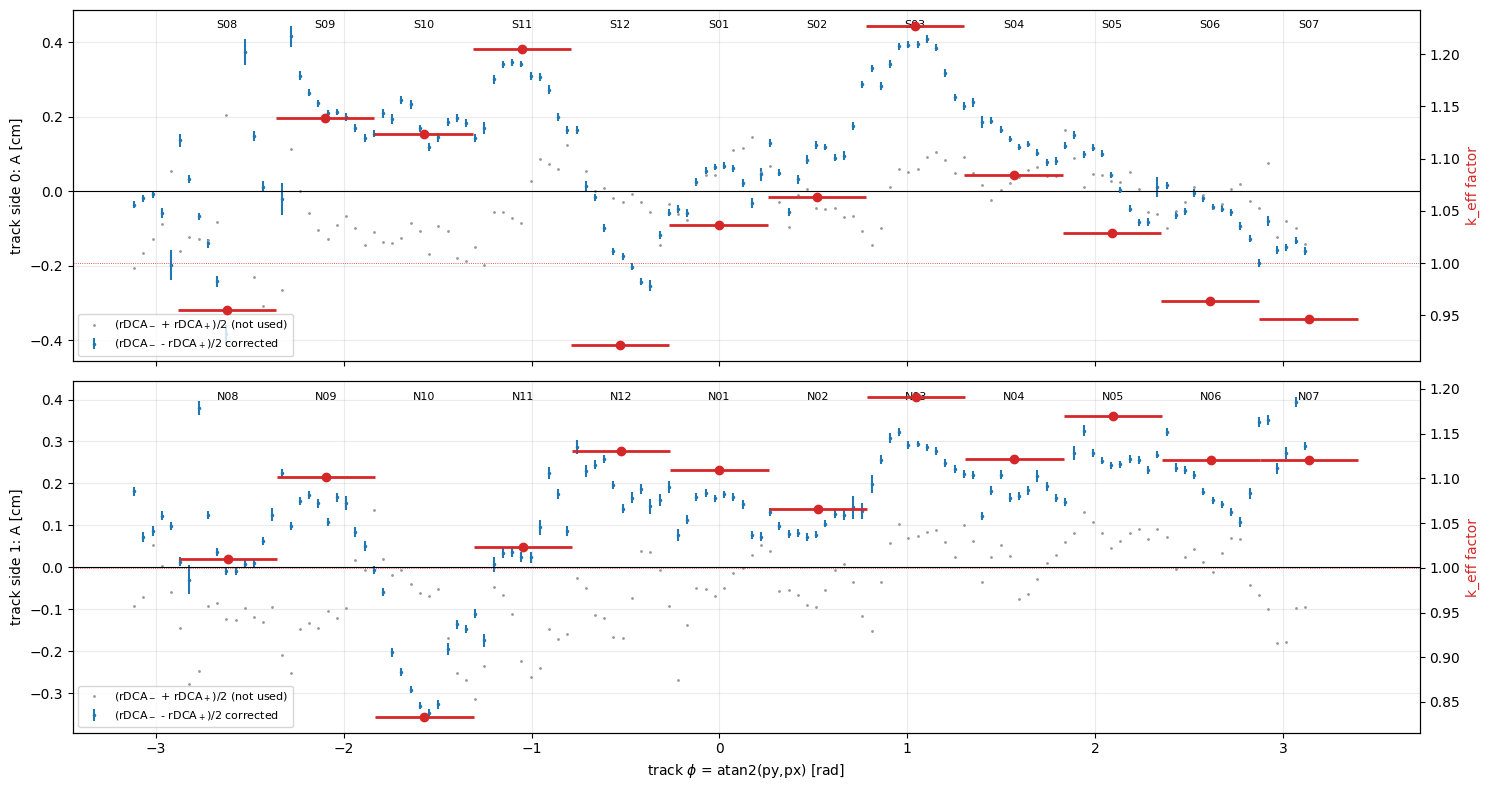

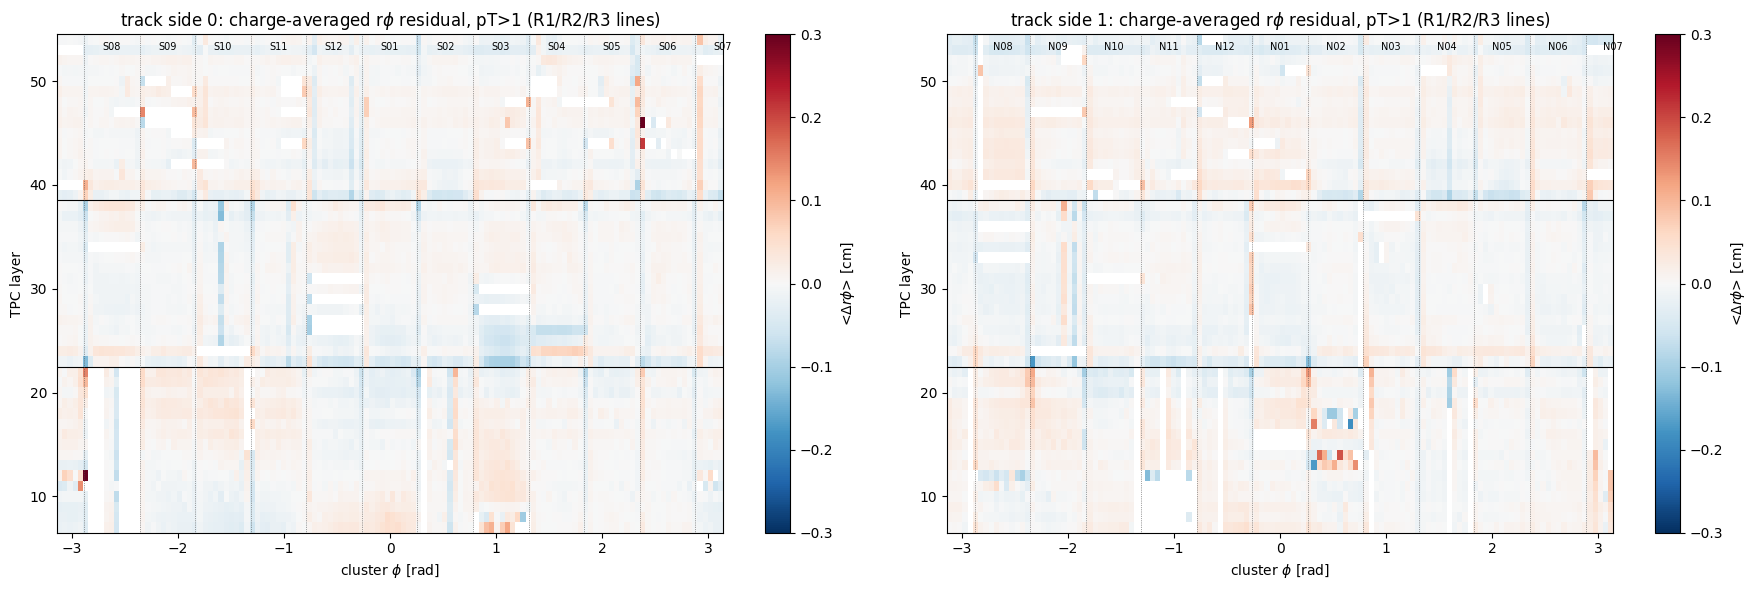

mean charge-averaged r-phi residual per module [cm] (R1, R2, R3):
R                  R1     R2     R3
track_side sec                     
0          S01  0.001 -0.003 -0.001
           S02  0.001 -0.001 -0.004
           S03  0.016 -0.015  0.004
           S04  0.002 -0.000 -0.001
           S05 -0.001  0.000 -0.003
           S06  0.000 -0.001 -0.004
           S07 -0.002 -0.001 -0.003
           S08 -0.014  0.003  0.000
           S09  0.004 -0.003 -0.001
           S10  0.007 -0.013  0.003
           S11  0.005 -0.004 -0.000
           S12 -0.002  0.001 -0.011
1          N01  0.012 -0.009  0.005
           N02  0.005 -0.002 -0.002
           N03  0.005 -0.003  0.002
           N04 -0.005  0.004 -0.008
           N05 -0.002  0.001 -0.001
           N06  0.003 -0.005  0.002
           N07  0.012 -0.010  0.006
           N08  0.006 -0.009  0.009
           N09  0.007 -0.009 -0.000
           N10 -0.003 -0.003  0.001
           N11  0.004 -0.006 -0.000
           N12  0.003 -0.009  0.00

In [4]:
# ============================================================
# k_eff per sector from residual rDCA vs phi
#
# Without correction rDCA < 0 for positive and > 0 for negative tracks. The
# charge-antisymmetric part A = (rdca_neg - rdca_pos)/2 is the distortion part;
# f = A_corrected / A_uncorrected is the fraction still uncorrected
# (f > 0: under-corrected -> more IBF). The symmetric part (rdca_neg + rdca_pos)/2
# (alignment / beam spot) is only reported.
# First-order, sector-local: the field at one phi also feels the neighbouring
# sectors, so iterate (map -> PHGarfield -> reco -> rDCA -> update; factors multiply).
# ============================================================
def read_rdca(path):
    d = pd.read_csv(path, comment="#", skipinitialspace=True)
    need = {"side", "charge", "phi", "rdca_cm"}
    if not need.issubset(d.columns):
        raise KeyError(f"{path} needs columns {sorted(need)} (+ err_cm)")
    if "err_cm" not in d:
        d["err_cm"] = 0.01
    d["phi"] = wrap_phi(d["phi"].to_numpy(float))
    return d

def antisym(d, side):
    p = d[(d.side == side) & (d.charge > 0)].sort_values("phi")
    n = d[(d.side == side) & (d.charge < 0)].sort_values("phi")
    phi = p["phi"].to_numpy(float)
    rn = np.interp(phi, n["phi"].to_numpy(float), n["rdca_cm"].to_numpy(float), period=TWO_PI)
    en = np.interp(phi, n["phi"].to_numpy(float), n["err_cm"].to_numpy(float), period=TWO_PI)
    rp, ep = p["rdca_cm"].to_numpy(float), p["err_cm"].to_numpy(float)
    ok = (np.abs(rp) < RDCA_MAX_ABS_CM) & (np.abs(rn) < RDCA_MAX_ABS_CM)
    return phi[ok], 0.5*(rn - rp)[ok], 0.5*np.hypot(en, ep)[ok], 0.5*(rn + rp)[ok]

def read_rdca_root(path):
    """Median rDCA per phi bin (same recipe as resid_with_cluster_maps_QA_phase_space.ipynb),
    x = atan2(px,py) converted to phi = atan2(py,px) = pi/2 - x."""
    f = root.TFile.Open(str(path))
    rows = []
    for side in (0, 1):
        for q, qn in ((1, "qplus"), (-1, "qminus")):
            h3 = f.Get(f"side{side}_{qn}/h_rDCAzero_vs_atan2_px_py_vs_pt")
            if not h3:
                raise KeyError(f"side{side}_{qn}/h_rDCAzero_vs_atan2_px_py_vs_pt in {path}")
            h3.GetZaxis().SetRange(h3.GetZaxis().FindBin(RDCA_PT_RANGE[0] + 1e-6), h3.GetZaxis().FindBin(RDCA_PT_RANGE[1] - 1e-6))
            h2 = h3.Project3D("yx")      # x = atan2(px,py), y = rDCA
            h2.SetDirectory(0)
            if RDCA_PHI_REBIN > 1:
                h2.RebinX(RDCA_PHI_REBIN)
            for ix in range(1, h2.GetNbinsX() + 1):
                sl = h2.ProjectionY(f"_sl_{side}{qn}{ix}", ix, ix); sl.SetDirectory(0)
                sl.GetXaxis().SetRange(sl.GetXaxis().FindBin(-3.0), sl.GetXaxis().FindBin(3.0))
                n_ = sl.Integral()
                if n_ < RDCA_MIN_ENTRIES:
                    continue
                qv = array("d", [0.0]); sl.GetQuantiles(1, qv, array("d", [0.5]))
                x = h2.GetXaxis().GetBinCenter(ix)
                rows.append({"side": side, "charge": q, "phi": float(wrap_phi(math.pi/2 - x)), "x_atan2_px_py": x,
                             "rdca_cm": float(qv[0]), "err_cm": float(1.253*sl.GetRMS()/math.sqrt(n_)), "n": n_})
    f.Close()
    return pd.DataFrame(rows)

RDCA_TABLE = []
_rdca_src = None
if RDCA_ROOT_FILE is not None and Path(RDCA_ROOT_FILE).exists():
    dres = read_rdca_root(RDCA_ROOT_FILE); _rdca_src = f"{RDCA_ROOT_FILE} (pT {RDCA_PT_RANGE})"
    dunc = read_rdca_root(RDCA_UNCORRECTED_ROOT_FILE) if RDCA_UNCORRECTED_ROOT_FILE and Path(RDCA_UNCORRECTED_ROOT_FILE).exists() else None
    dres.to_csv(OUTPUT_DIR/"rdca_median_vs_phi_used.csv", index=False)
elif RDCA_RESIDUAL_FILE.exists():
    dres = read_rdca(RDCA_RESIDUAL_FILE); _rdca_src = str(RDCA_RESIDUAL_FILE)
    dunc = read_rdca(RDCA_UNCORRECTED_FILE) if RDCA_UNCORRECTED_FILE.exists() else None
if _rdca_src is not None:
    RDCA_KEFF.clear()
    for tside in (0, 1):
        gside = RDCA_TRACK_SIDE_TO_GAIN_SIDE[tside]
        phi, A, eA, S = antisym(dres, tside)
        if dunc is not None:
            pu, Au, _, _ = antisym(dunc, tside)
            A0 = np.interp(phi, pu, Au, period=TWO_PI)
        else:
            A0 = np.full_like(A, RDCA_D0_CM)
        f = np.divide(A, A0, out=np.zeros_like(A), where=np.abs(A0) > 1e-3)
        dc_side = 1 - gside if GAIN_INDEXING == "idealpadmap_swapped" else gside
        for k in range(12):
            row = ROWS[("Z", 0, 8)]
            ph = np.array([global_phi(row, dc_side, k, ip) for ip in range(row["n"])])
            c = ph[row["n"]//2]
            sel = np.abs(np.arctan2(np.sin(phi - c), np.cos(phi - c))) < math.pi/12
            if np.count_nonzero(sel) == 0:
                fk, ek = 0.0, np.nan
            else:
                w = 1/np.maximum(eA[sel]/np.abs(A0[sel]), 1e-3)**2
                o = np.argsort(f[sel]); cw = np.cumsum(w[o])/np.sum(w)
                fk = float(f[sel][o][np.searchsorted(cw, 0.5)])
                ek = float(1/np.sqrt(np.sum(w)))
            RDCA_TABLE.append({"track_side": tside, "gain_side": gside, "dc_side": dc_side, "dc_sector": k,
                               "module": module_label(dc_side, k, 0)[:3], "phi_center": c,
                               "f_uncorrected": fk, "f_err": ek, "n_bins": int(np.count_nonzero(sel)),
                               "sym_rdca_cm": float(np.median(S[sel])) if np.any(sel) else np.nan})
    RDCA_TABLE = pd.DataFrame(RDCA_TABLE)
    RDCA_TABLE["keff_factor"] = np.clip(1 + RDCA_RELAXATION*RDCA_TABLE["f_uncorrected"], *RDCA_KEFF_CLIP)
    if RDCA_KEEP_MEAN:
        RDCA_TABLE["keff_factor"] /= RDCA_TABLE.groupby("dc_side")["keff_factor"].transform("mean")
    for _, r in RDCA_TABLE.iterrows():
        RDCA_KEFF[(int(r.dc_side), int(r.dc_sector))] = float(r.keff_factor)
    RDCA_TABLE.to_csv(OUTPUT_DIR/"keff_from_rdca.csv", index=False)
    print(RDCA_TABLE[["track_side", "module", "dc_side", "dc_sector", "n_bins", "f_uncorrected", "f_err", "keff_factor",
                      "sym_rdca_cm"]].round(3).to_string(index=False))
    print("source:", _rdca_src, "| uncorrected:", RDCA_UNCORRECTED_FILE if dunc is not None else f"D0={RDCA_D0_CM} cm",
          "| applied to modules", [f"R{m+1}" for m in RDCA_KEFF_MODULES])

    fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
    for tside, ax in zip((0, 1), axes):
        gside = RDCA_TRACK_SIDE_TO_GAIN_SIDE[tside]
        phi, A, eA, S = antisym(dres, tside)
        ax.errorbar(phi, A, eA, fmt=".", ms=3, label="(rDCA$_-$ - rDCA$_+$)/2 corrected")
        ax.plot(phi, S, ".", ms=2, color="0.6", label="(rDCA$_-$ + rDCA$_+$)/2 (not used)")
        t = RDCA_TABLE[RDCA_TABLE.track_side == tside]
        ax2 = ax.twinx()
        ax2.hlines(t.keff_factor, t.phi_center - math.pi/12, t.phi_center + math.pi/12, color="C3", lw=2)
        ax2.plot(t.phi_center, t.keff_factor, "o", color="C3", label="k_eff factor")
        ax2.axhline(1.0, color="C3", lw=0.6, ls=":")
        for _, r in t.iterrows():
            ax.text(r.phi_center, ax.get_ylim()[1]*0.9 if ax.get_ylim()[1] > 0 else 0.1, r.module, ha="center", fontsize=8)
        ax.axhline(0, color="k", lw=0.8); ax.set_ylabel(f"track side {tside}: A [cm]"); ax2.set_ylabel("k_eff factor", color="C3")
        ax.legend(fontsize=8, loc="lower left"); ax.grid(alpha=0.25)
    axes[-1].set_xlabel(r"track $\phi$ = atan2(py,px) [rad]")
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/"keff_from_rdca.png", dpi=140); plt.show()
else:
    print("No rDCA input (", RDCA_ROOT_FILE, "/", RDCA_RESIDUAL_FILE, ") -> no k_eff correction.")

# ------------------------------------------------------------
# QA: charge-averaged cluster r-phi residual vs layer and cluster phi (true phi),
# with module and sector boundaries. Shows R1/R2/R3 structure inside a sector,
# which the rDCA alone cannot separate. Not used for the correction.
# ------------------------------------------------------------
if RDCA_ROOT_FILE is not None and Path(RDCA_ROOT_FILE).exists():
    f = root.TFile.Open(str(RDCA_ROOT_FILE))
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    RESID_MODULE_TABLE = []
    for tside, ax in zip((0, 1), axes):
        acc_s = None; acc_w = None
        for qn in ("qplus", "qminus"):
            p = f.Get(f"side{tside}_{qn}/h_mean_residual_rphi_vs_layer_phi_pt1")
            nx, ny = p.GetNbinsX(), p.GetNbinsY()
            m = np.array([[p.GetBinContent(i, j) for i in range(1, nx + 1)] for j in range(1, ny + 1)])
            w = np.array([[p.GetBinEntries(p.GetBin(i, j)) for i in range(1, nx + 1)] for j in range(1, ny + 1)])
            acc_s = m*w if acc_s is None else acc_s + m*w; acc_w = w if acc_w is None else acc_w + w
        mean = np.divide(acc_s, acc_w, out=np.full_like(acc_s, np.nan), where=acc_w > 20)
        pe = np.array([p.GetYaxis().GetBinLowEdge(j) for j in range(1, ny + 2)])
        le = np.array([p.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
        im = ax.pcolormesh(pe, le, mean.T, cmap="RdBu_r", vmin=-0.3, vmax=0.3, shading="flat")
        fig.colorbar(im, ax=ax, label=r"<$\Delta r\phi$> [cm]")
        for y in (22.5, 38.5):
            ax.axhline(y, color="k", lw=0.8)
        gside = RDCA_TRACK_SIDE_TO_GAIN_SIDE[tside]; dc_side = 1 - gside if GAIN_INDEXING == "idealpadmap_swapped" else gside
        pc = 0.5*(pe[1:] + pe[:-1]); lc = 0.5*(le[1:] + le[:-1])
        for kk in range(12):
            row = ROWS[("Z", 0, 8)]
            ph = np.array([global_phi(row, dc_side, kk, ip) for ip in range(row["n"])]); c = ph[row["n"]//2]
            ax.axvline(wrap_phi(c + math.pi/12), color="0.3", lw=0.5, ls=":")
            lab = module_label(dc_side, kk, 0)[:3]
            ax.text(c, 53.0, lab, ha="center", fontsize=7)
            sel = np.abs(np.arctan2(np.sin(pc - c), np.cos(pc - c))) < math.pi/12*0.8
            for mod, (lo, hi) in enumerate(((7, 22), (23, 38), (39, 54))):
                ls_ = (lc >= lo) & (lc <= hi)
                RESID_MODULE_TABLE.append({"track_side": tside, "module": f"{lab}R{mod+1}", "dc_side": dc_side,
                                           "dc_sector": kk, "mean_resid_rphi_cm": float(np.nanmean(mean[np.ix_(sel, ls_)]))})
        ax.set_xlabel(r"cluster $\phi$ [rad]"); ax.set_ylabel("TPC layer")
        ax.set_title(f"track side {tside}: charge-averaged r$\phi$ residual, pT>1 (R1/R2/R3 lines)")
    f.Close()
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/"cluster_resid_rphi_vs_layer_phi.png", dpi=140); plt.show()
    RESID_MODULE_TABLE = pd.DataFrame(RESID_MODULE_TABLE)
    RESID_MODULE_TABLE.to_csv(OUTPUT_DIR/"cluster_resid_rphi_per_module.csv", index=False)
    print("mean charge-averaged r-phi residual per module [cm] (R1, R2, R3):")
    print(RESID_MODULE_TABLE.assign(R=RESID_MODULE_TABLE.module.str[-2:], sec=RESID_MODULE_TABLE.module.str[:3])
          .pivot_table(index=["track_side", "sec"], columns="R", values="mean_resid_rphi_cm").round(3).to_string())


## Generate maps

In [5]:
# ============================================================
# Generate: one ROOT file per alpha (+ tuned gain file), same names as the v35 maps
# ============================================================
def write_th2(name, title, a, phi_edges):
    h = root.TH2D(name, title, len(phi_edges) - 1, array("d", phi_edges), NR, array("d", R_EDGES))
    h.SetDirectory(0)
    for ir in range(NR):
        for ip in range(a.shape[1]):
            if a[ir, ip] > 0:
                h.SetBinContent(ip + 1, ir + 1, float(a[ir, ip]))
    h.Write()

def tuned_gain_file(path):
    f = root.TFile(str(path), "RECREATE")
    for gs, name in enumerate(GAIN_HISTS):
        h = GAIN_RAW[f"hist{gs}"].Clone(name); h.SetDirectory(0)
        t = np.ones(12)
        for s in (0, 1):
            for k in range(12):
                g_s, g_k = gain_index(s, k)
                if g_s == gs:
                    t[g_k] = SECTOR_GAIN_TUNE[s][k]
        for ix in range(1, 13):
            for iy in range(1, h.GetNbinsY() + 1):
                h.SetBinContent(ix, iy, h.GetBinContent(ix, iy)*t[ix - 1])
        h.Write()
    f.Close()

# DC side -> physical side. gain-map side 0 is "South" (hGainMap_side0_South); DC side s
# uses gain-map side 1-s (verified on 19 runs), so DC side 0 = North, DC side 1 = South.
PHYS_SIDE = {s: ("South" if gain_index(s, 0)[0] == 0 else "North") for s in (0, 1)}
print("histogram side naming: DC side 0 =", PHYS_SIDE[0], "| DC side 1 =", PHYS_SIDE[1])

GENERATED = {}
for choice in ALPHAS:
    tag = "data" if choice == "data" else f"alpha{float(choice):.2f}".replace(".", "p")
    path = OUTPUT_DIR/f"TPC_phgarfield_generated_{tag}.root"
    f = root.TFile(str(path), "RECREATE")
    for s in (0, 1):
        p = params_for(choice, s)
        rad = radial_bins(p)
        G = gain_matrix(s)
        GENERATED[(tag, s)] = {"params": p, "radial": rad}
        for n in PHI_BINS:
            edges, live = LIVE[(s, n)]
            prim = rad[:, None]*live.sum(axis=1)
            ibf = rad[:, None]*np.einsum("rkp,rk->rp", live, G)
            sfx = "" if n == PHI_BINS[0] else f"_nphi{n}"
            lab = f"alpha={p['alpha']:.3f} r0={p['r0']:.2f} w={p['width']:.2f}"
            write_th2(f"h_primary_phgarfield_real{sfx}_side{s}", f"generated primary {lab} DC side {s};#phi [rad];r [cm]", prim, edges)
            write_th2(f"h_ibf_phgarfield_real{sfx}_side{s}", f"generated primary x gain x tune x k_eff {lab} DC side {s};#phi [rad];r [cm]", ibf, edges)
            # Same maps under the PHYSICAL side name (South = z<0 = gain-map side 0 = track side 0).
            # Use these in PHGarfieldRossegger: setDensityMapFile(file, *_South, *_North).
            phys = PHYS_SIDE[s]
            write_th2(f"h_primary_phgarfield_real{sfx}_{phys}", f"generated primary {lab} {phys} (DC side {s});#phi [rad];r [cm]", prim, edges)
            write_th2(f"h_ibf_phgarfield_real{sfx}_{phys}", f"generated primary x gain x tune x k_eff {lab} {phys} (DC side {s});#phi [rad];r [cm]", ibf, edges)
            GENERATED[(tag, s, n)] = (prim, ibf, edges)
        h = root.TH1D(f"h_radial_side{s}", f"generated radial profile side {s};r [cm];density", NR, array("d", R_EDGES))
        for ir, v in enumerate(rad):
            h.SetBinContent(ir + 1, float(v))
        h.Write()
    root.TNamed("generator", f"rho=(Rref/r)^alpha*T(r)*D(r), Rref={R_REF}; side0={params_for(choice,0)} "
                f"side1={params_for(choice,1)}; turn_on={TURN_ON}; dip={DIP}; gain={APPLY_GAIN} ({GAIN_INDEXING}); "
                f"tune={SECTOR_GAIN_TUNE}; dead_stripes={DEAD_STRIPE_FILE if DEAD else 'none'}; "
                f"k_eff={'rDCA ' + str(_rdca_src) if RDCA_KEFF else 'none'} (IBF maps only); "
                f"histogram side{{0,1}} = DC side, {PHYS_SIDE[0]}/{PHYS_SIDE[1]}; *_South/*_North = physical side").Write()
    f.Close()
    print("wrote", path)
tuned_gain_file(OUTPUT_DIR/"TPC_gain_tuned_generated.root")
print("wrote", OUTPUT_DIR/"TPC_gain_tuned_generated.root")


histogram side naming: DC side 0 = North | DC side 1 = South


wrote output_dc/generated_maps/TPC_phgarfield_generated_data.root


wrote output_dc/generated_maps/TPC_phgarfield_generated_alpha1p25.root


wrote output_dc/generated_maps/TPC_phgarfield_generated_alpha1p60.root


wrote output_dc/generated_maps/TPC_phgarfield_generated_alpha2p00.root
wrote output_dc/generated_maps/TPC_gain_tuned_generated.root


## QA

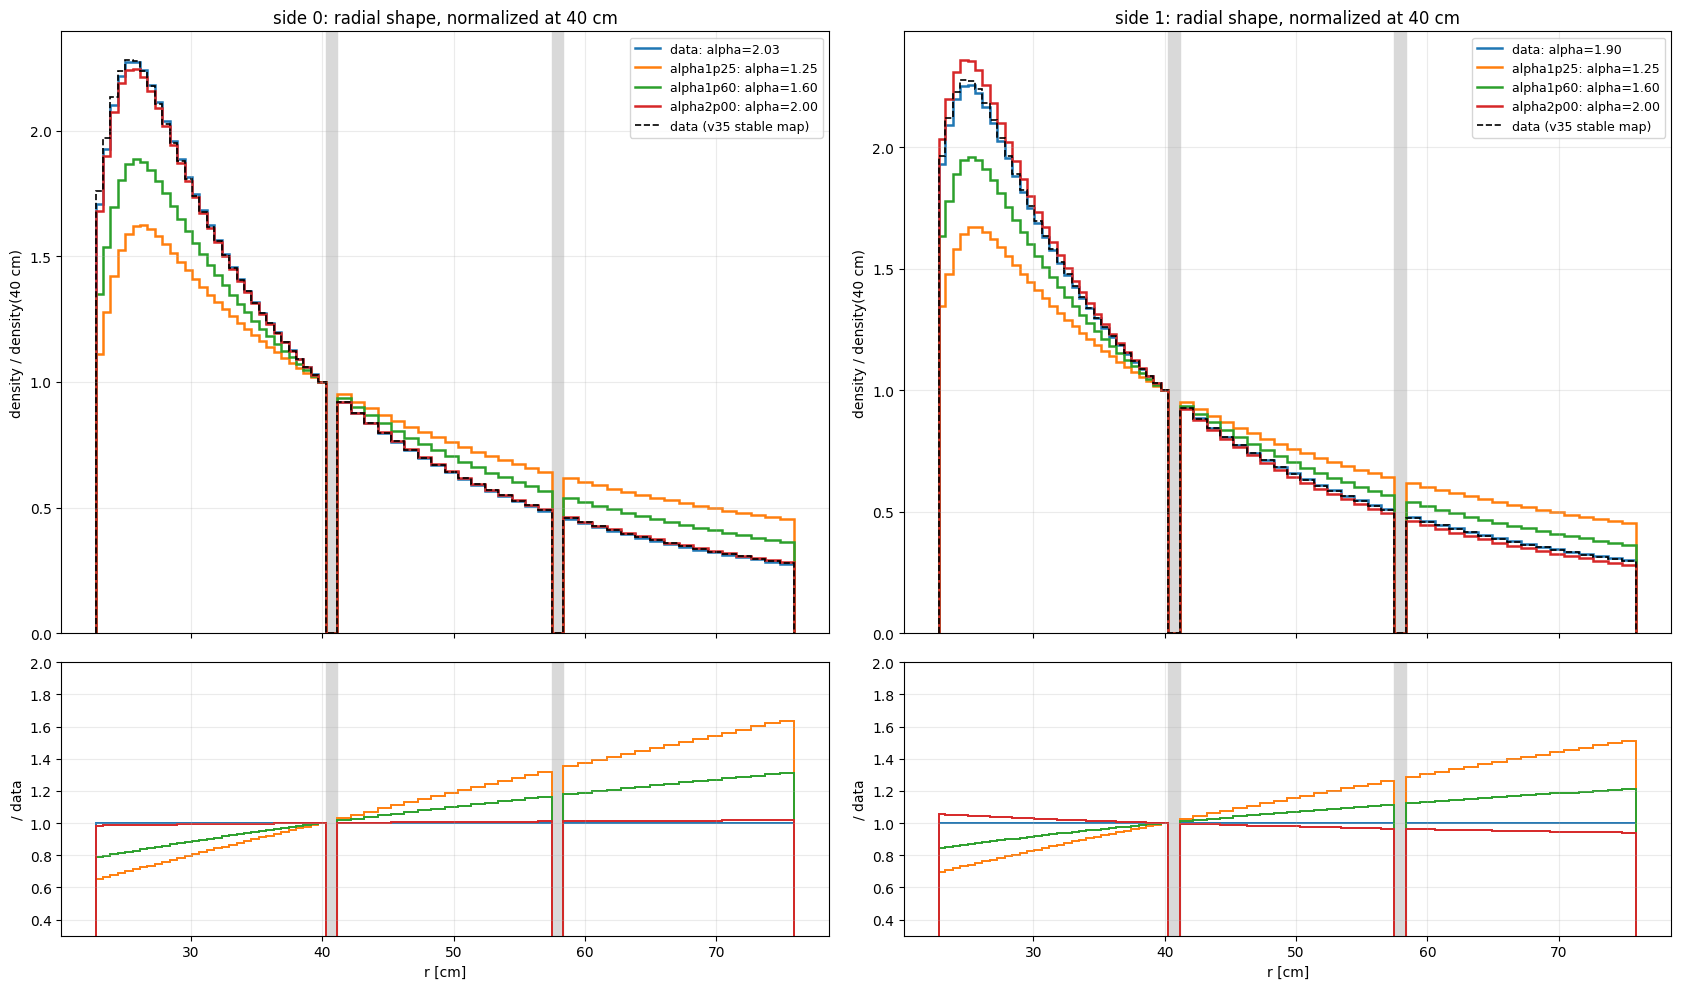

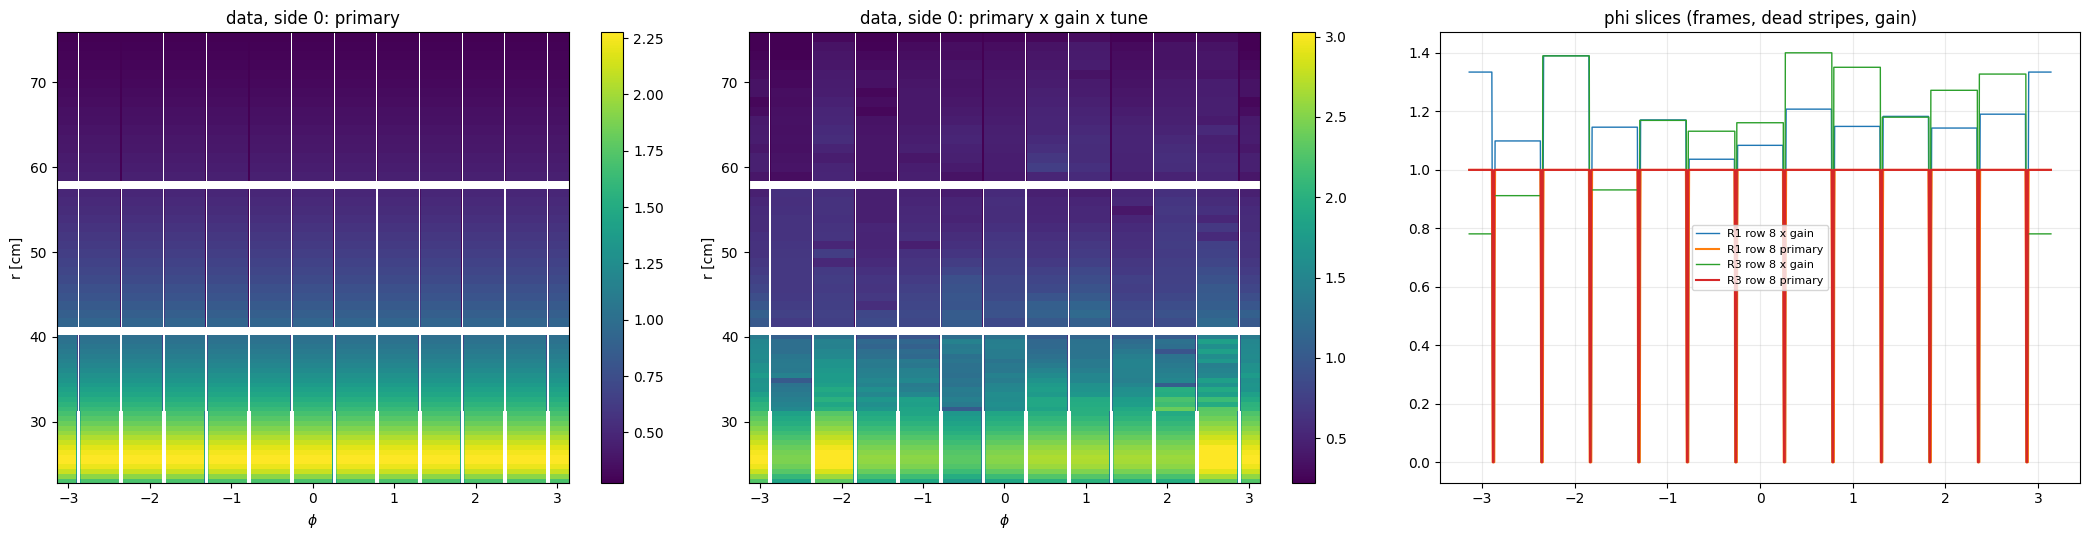

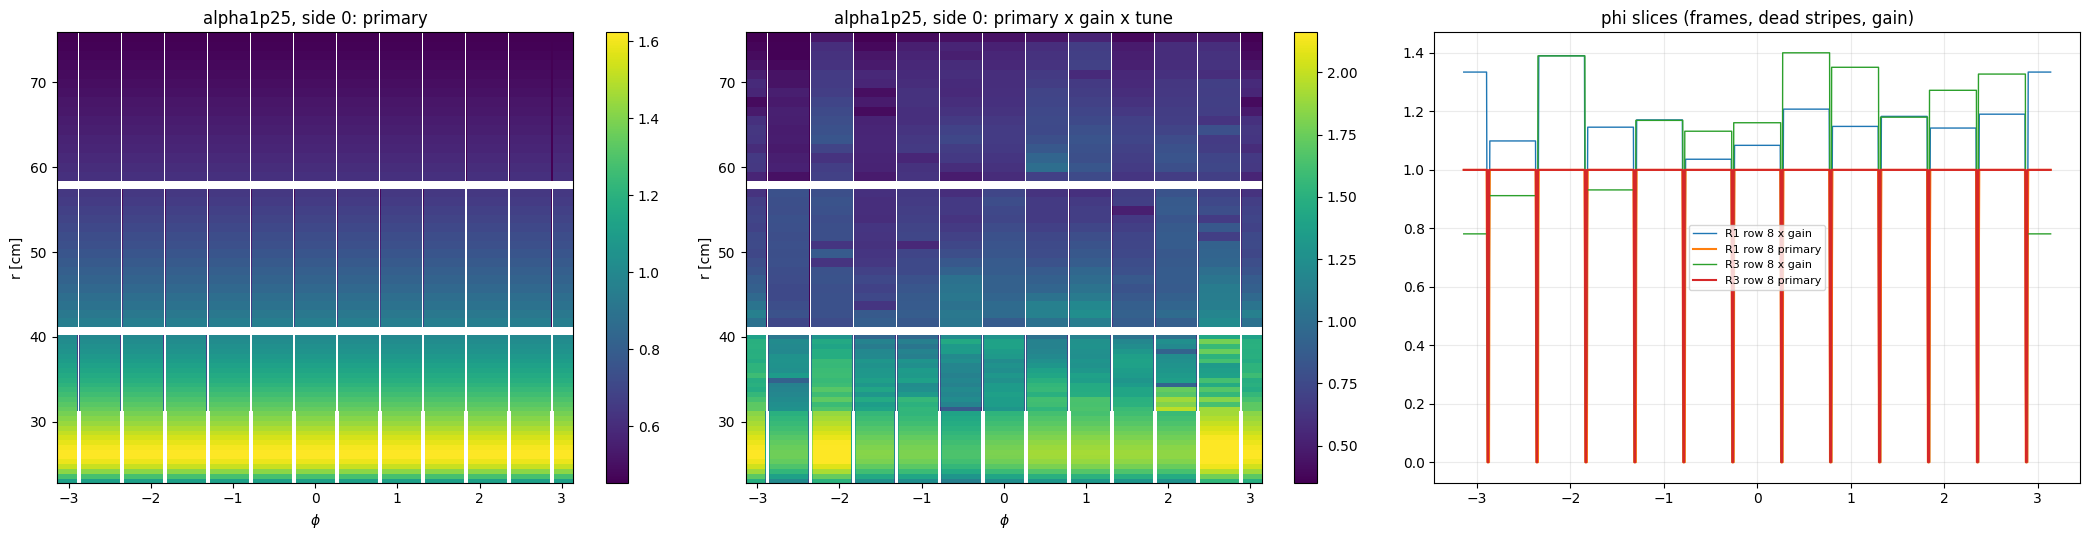

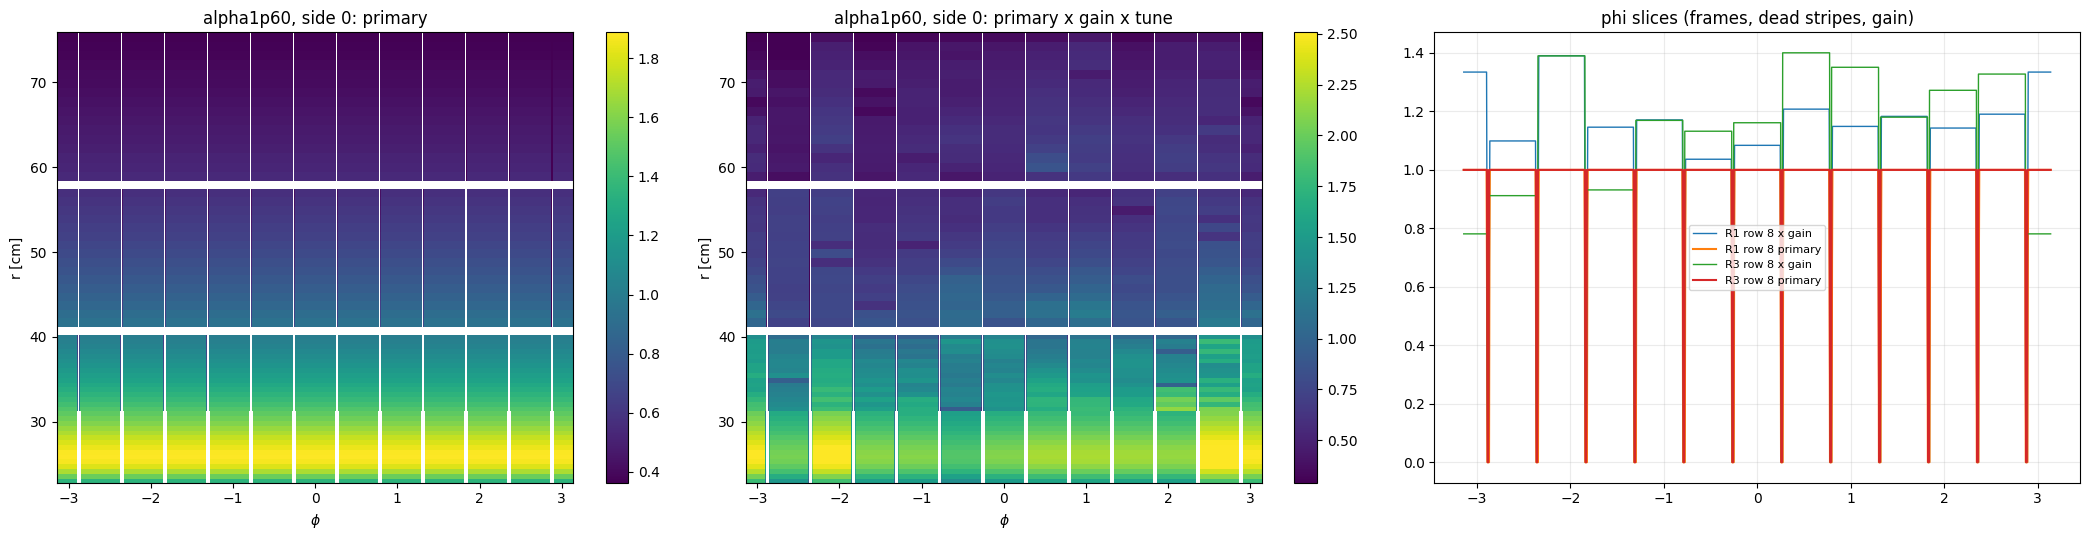

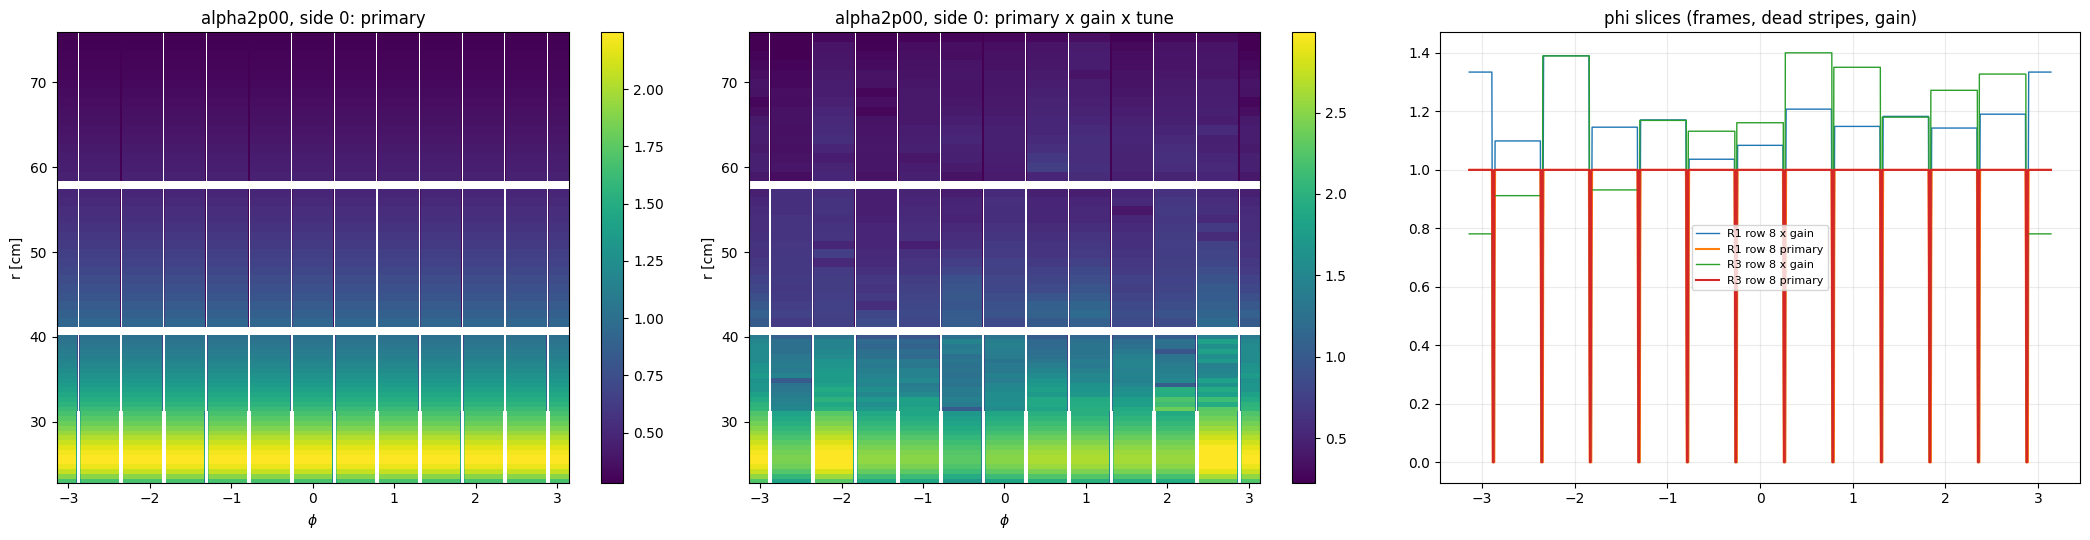

plots in output_dc/generated_maps


/tmp/ipykernel_78988/3875960792.py:56: RuntimeWarning: All-NaN slice encountered
  prof = np.nanmedian(np.where(a[rows] > 0, a[rows], np.nan), axis=0)


S side (DC side 1): corr(k_eff, dc_measured/gain_map) over 12 sectors = +0.18
   sector : ['S06', 'S05', 'S04', 'S03', 'S02', 'S01', 'S12', 'S11', 'S10', 'S09', 'S08', 'S07']
   k_eff  : [0.964, 1.029, 1.084, 1.227, 1.064, 1.037, 0.921, 1.204, 1.124, 1.139, 0.955, 0.947]
   DC/gain: [0.998, 1.004, 1.037, 0.938, 0.95, 0.998, 0.915, 1.062, 0.987, 1.054, 0.933, 1.099]


N side (DC side 0): corr(k_eff, dc_measured/gain_map) over 12 sectors = -0.18
   sector : ['N06', 'N05', 'N04', 'N03', 'N02', 'N01', 'N12', 'N11', 'N10', 'N09', 'N08', 'N07']
   k_eff  : [1.12, 1.17, 1.122, 1.191, 1.065, 1.11, 1.131, 1.023, 0.834, 1.102, 1.009, 1.121]
   DC/gain: [0.751, 0.975, 0.925, 1.058, 0.94, 0.998, 0.805, 1.044, 1.083, 0.863, 0.768, 1.099]


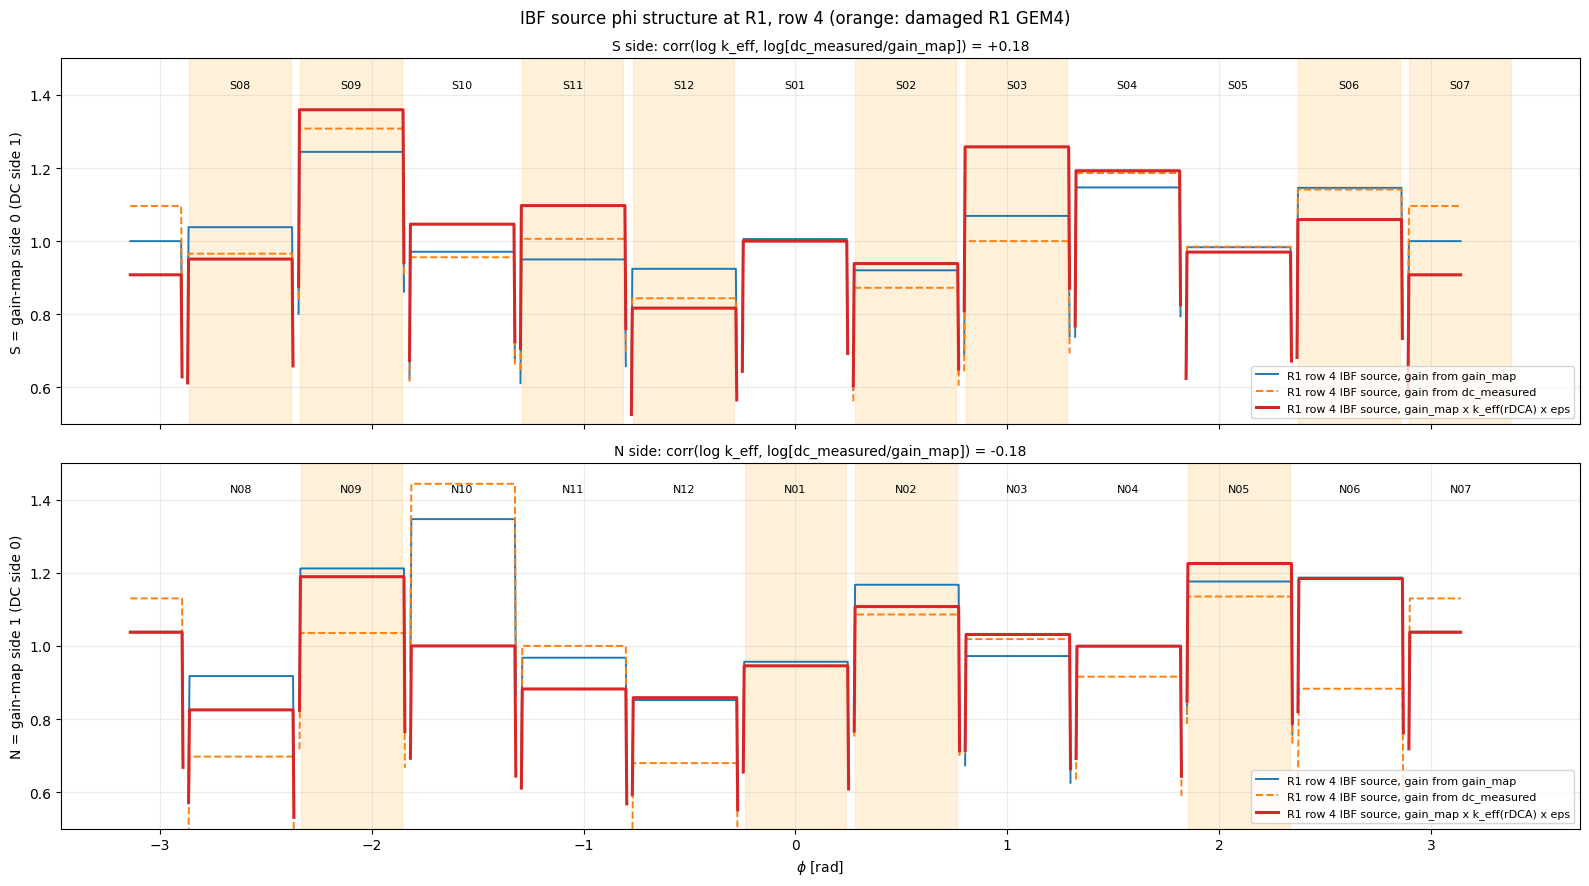

In [6]:
# ============================================================
# QA: radial shapes vs data, maps, phi slices
# ============================================================
def data_radial(side):
    if not DATA_STABLE_FILE.exists():
        return None
    f = root.TFile.Open(str(DATA_STABLE_FILE))
    h = f.Get(f"h_primary_stable_radial_side{side}")
    v = np.array([h.GetBinContent(i + 1) for i in range(h.GetNbinsX())]) if h and h.GetNbinsX() == NR else None
    f.Close()
    return v

tags = list(dict.fromkeys(k[0] for k in GENERATED if len(k) == 2))
irref = int(np.argmin(np.abs(0.5*(R_EDGES[1:] + R_EDGES[:-1]) - R_REF)))
fig, axes = plt.subplots(2, 2, figsize=(17, 10), gridspec_kw={"height_ratios": [2.2, 1]}, sharex=True)
for s in (0, 1):
    ax, axr = axes[0, s], axes[1, s]
    dat = data_radial(s)
    ref = GENERATED[(tags[0], s)]["radial"]
    for tag in tags:
        v = GENERATED[(tag, s)]["radial"]; v = v/v[irref]
        ax.stairs(v, R_EDGES, lw=1.8, label=f"{tag}: alpha={GENERATED[(tag, s)]['params']['alpha']:.2f}")
        axr.stairs(np.divide(v, ref/ref[irref], out=np.full_like(v, np.nan), where=ref > 0), R_EDGES, lw=1.4)
    if dat is not None:
        ax.stairs(dat/dat[irref], R_EDGES, color="k", ls="--", lw=1.2, label="data (v35 stable map)")
    for ir, kd in enumerate(R_KIND):
        if kd[0] == "gap":
            for a_ in (ax, axr):
                a_.axvspan(R_EDGES[ir], R_EDGES[ir + 1], color="0.85", zorder=0)
    ax.set_title(f"side {s}: radial shape, normalized at {R_REF:.0f} cm"); ax.set_ylabel("density / density(40 cm)")
    ax.grid(alpha=0.25); ax.legend(fontsize=9)
    axr.set_ylabel(f"/ {tags[0]}"); axr.set_xlabel("r [cm]"); axr.grid(alpha=0.25); axr.set_ylim(0.3, 2.0)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"generated_radial_shapes.png", dpi=140); plt.show()

n = PHI_BINS[-1]
for tag in tags:
    fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
    prim, ibf, edges = GENERATED[(tag, 0, n)]
    for ax, a, t in ((axes[0], prim, "primary"), (axes[1], ibf, "primary x gain x tune")):
        v = a[a > 0]
        im = ax.pcolormesh(edges, R_EDGES, np.where(a > 0, a, np.nan), shading="flat",
                           vmin=np.percentile(v, 1), vmax=np.percentile(v, 99))
        fig.colorbar(im, ax=ax); ax.set_title(f"{tag}, side 0: {t}"); ax.set_xlabel(r"$\phi$"); ax.set_ylabel("r [cm]")
    pc = 0.5*(edges[1:] + edges[:-1])
    for kd_i, lab in ((next(i for i, k in enumerate(R_KIND) if k == ("Z", 0, 8)), "R1 row 8"),
                      (next(i for i, k in enumerate(R_KIND) if k == ("Z", 2, 8)), "R3 row 8")):
        axes[2].plot(pc, ibf[kd_i]/prim[kd_i].max(), lw=1, label=f"{lab} x gain")
        axes[2].plot(pc, prim[kd_i]/prim[kd_i].max(), lw=1.5, label=f"{lab} primary")
    axes[2].set_title("phi slices (frames, dead stripes, gain)"); axes[2].legend(fontsize=8); axes[2].grid(alpha=0.25)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/f"generated_map_{tag}.png", dpi=130); plt.show()
print("plots in", OUTPUT_DIR)

# ------------------------------------------------------------
# Sector structure of the IBF source vs phi, in the gain-map side naming used by the
# rDCA plots (S = gain-map side 0, N = side 1). R1 modules with a damaged GEM4 shaded.
# ------------------------------------------------------------
n = PHI_BINS[-1]
_saved = GAIN_SOURCE
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
for gside, ax in zip((0, 1), axes):
    s = 1 - gside if GAIN_INDEXING == "idealpadmap_swapped" else gside
    edges, live = LIVE[(s, n)]; pc = 0.5*(edges[1:] + edges[:-1])
    irow = next(i for i, k in enumerate(R_KIND) if k == ("Z", 0, 4))
    sector_G = {}
    for src, st, eps, lab in (("gain_map", "-", False, "gain from gain_map"),
                              ("dc_measured", "--", False, "gain from dc_measured"),
                              ("gain_map", "-", True, "gain_map x k_eff(rDCA) x eps")):
        if eps and not RDCA_KEFF and IBF_EPS_DAMAGED_G4 == 1.0 and not IBF_EPS_OVERRIDE:
            continue
        try:
            GAIN_SOURCE = src
            G = gain_matrix(s, with_eps=eps)
        except FileNotFoundError:
            continue
        sector_G[lab] = G[irow]/np.median(G[irow])
        prof = np.einsum("kp,k->p", live[irow], G[irow])
        ax.plot(pc, np.where(prof > 0, prof/np.median(prof[prof > 0]), np.nan), st, lw=2.2 if eps else 1.4,
                color="C3" if eps else None, label=f"R1 row 4 IBF source, {lab}")
    GAIN_SOURCE = _saved
    # Is the rDCA correction gain-like? Compare k_eff with dc_measured / gain_map per sector.
    if "gain from dc_measured" in sector_G and RDCA_KEFF:
        ratio = sector_G["gain from dc_measured"]/sector_G["gain from gain_map"]
        keff = np.array([RDCA_KEFF.get((s, k), 1.0) for k in range(12)])
        c = float(np.corrcoef(np.log(ratio), np.log(keff))[0, 1])
        ax.set_title(f"{'S' if gside == 0 else 'N'} side: corr(log k_eff, log[dc_measured/gain_map]) = {c:+.2f}", fontsize=10)
        print(f"{'S' if gside == 0 else 'N'} side (DC side {s}): corr(k_eff, dc_measured/gain_map) over 12 sectors = {c:+.2f}")
        print("   sector :", [module_label(s, k, 0)[:3] for k in range(12)])
        print("   k_eff  :", np.round(keff, 3).tolist())
        print("   DC/gain:", np.round(ratio, 3).tolist())
    for k in range(12):
        lab = module_label(s, k, 0)
        row = ROWS[("Z", 0, 4)]
        ph = np.array([global_phi(row, s, k, ip) for ip in range(row["n"])]); c = ph[row["n"]//2]
        ax.text(c, 1.42, lab[:3], ha="center", fontsize=8)
        if UNDAMAGED is not None and lab + "G4" not in UNDAMAGED:
            ax.axvspan(c - 0.24, c + 0.24, color="orange", alpha=0.15, zorder=0)
    ax.set_ylim(0.5, 1.5); ax.grid(alpha=0.25); ax.legend(fontsize=8, loc="lower right")
    ax.set_ylabel(f"{'S' if gside == 0 else 'N'} = gain-map side {gside} (DC side {s})")
fig.suptitle("IBF source phi structure at R1, row 4 (orange: damaged R1 GEM4)")
axes[-1].set_xlabel(r"$\phi$ [rad]")
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"ibf_phi_structure_R1.png", dpi=140); plt.show()
